# Block 2 — sklearn Modelling Essentials

**Target: 2 hours. Real data: UCI Wine Quality.**

In [3]:
%pip install -U scikit-learn

Defaulting to user installation because normal site-packages is not writeable
  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   ------------------- -------------------- 3.9/8.2 MB 18.7 MB/s eta 0:00:01
   ----------------------------------- ---- 7.3/8.2 MB 18.6 MB/s eta 0:00:01
   ---------------------------------------- 8.2/8.2 MB 16.1 MB/s  0:00:00
   ---------------------------------------- 0.0/36.6 MB ? eta -:--:--
   ---- ----------------------------------- 3.7/36.6 MB 16.9 MB/s eta 0:00:02
   ------- -------------------------------- 6.8/36.6 MB 16.5 MB/s eta 0:00:02
   ----------- ---------------------------- 10.2/36.6 MB 16.3 MB/s eta 0:00:02
   -------------- ------------------------- 13.4/36.6 MB 16.2 MB/s eta 0:00:02
   ------------------ --------------------- 16.8/36.6 MB 16.2 MB/s eta 0:00:02
   ---------------------- ----------------- 20.4/36.6 MB 16.3 MB/s eta 0:00:01
   ---------


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: C:\Users\Startklar\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [4]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
ROOT=next((p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/"reference"/"dataset_loader.py").exists()),Path.cwd())
sys.path.insert(0,str(ROOT/"reference"))
from dataset_loader import load_checked_csv
URL="https://raw.githubusercontent.com/zygmuntz/wine-quality/master/winequality/winequality-red.csv"
df=load_checked_csv("wine_red.csv",URL,expected_cols=["fixed acidity","volatile acidity","alcohol","quality"],min_rows=1500,read_csv_kwargs={"sep":";"})
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## A. X/y and split
Target `quality`; 80/20 train/validation. Why is random split defensible here?

In [5]:
X = df.drop(columns = 'quality')
y = df['quality']

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42
)  # random split

# alternatively, we can also do 80/20 chronological split
# split = int(0.8 * len(df.index))
# X_train, X_valid = X.iloc[:split].copy(), X.iloc[split:].copy()
# ...

def metrics(y,p): 
    return {
        "rmse":mean_squared_error(y,p)**.5,
        "mae":mean_absolute_error(y,p),
        "r2":r2_score(y,p)
    }

## B. Baseline
Training-mean prediction; RMSE, MAE, R².

In [6]:
# validate first constant tranining mean baseline

baseline = np.repeat(y_train.mean(), len(y_valid))

print(metrics(y_valid, baseline))

{'rmse': 0.81065409945582, 'mae': 0.6852839132134478, 'r2': -0.005591701339940913}


## C. Ridge
StandardScaler → Ridge; alphas [0.1,1,10]; select on validation RMSE.

In [7]:
rows = []
best, best_rmse = None, np.inf

for a in [0.1, 1, 10]:
    m = Pipeline([
        ('scale', StandardScaler()),
        ('ridge', Ridge(alpha=a))
    ])
    m.fit(X_train, y_train)
    
    p = m.predict(X_valid)
    met = metrics(y_valid, p)

    rows.append({'model': 'Ridge', 'alpha': a, **met})

    if met['rmse'] < best_rmse:
        best_rmse = met['rmse']
        best = m

display(pd.DataFrame(rows))


,model,alpha,rmse,mae,r2
0,Ridge,0.1,0.624521,0.503533,0.403178
1,Ridge,1.0,0.624530,0.503560,0.403161
2,Ridge,10.0,0.624641,0.503822,0.402948


## D. Nonlinear
RandomForestRegressor or HistGradientBoostingRegressor; restrained settings.

In [ ]:
rf = RandomForestRegressor(
    n_estimators=300, 
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)
pred_rf = rf.predict(X_valid)
print("RF:", metrics(y_valid, pred_rf))

gbm = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=31,
    l2_regularization=1,
    random_state=42
)

gbm.fit(X_train, y_train)
pred_gbm = gbm.predict(X_valid)
print("GBM:", metrics(y_valid, pred_gbm))

pd.DataFrame(
    [metrics(y_valid, pred_rf), metrics(y_valid, pred_gbm)], 
    index=['RF', 'GBM']
)

RF: {'rmse': 0.5622501033723069, 'mae': 0.4372195734633695, 'r2': 0.5162626712413787}
GBM: {'rmse': 0.5709857176943627, 'mae': 0.4200670264445089, 'r2': 0.5011143586030736}


,rmse,mae,r2
RF,0.562250,0.437220,0.516263
GBM,0.570986,0.420067,0.501114


## E. Diagnostics
Actual-v-pred, residual-v-pred, RMSE by true quality, model-comparison table.

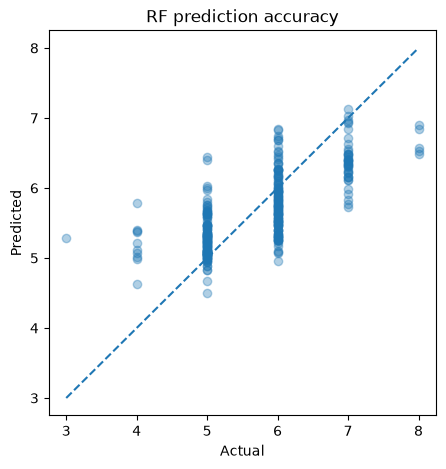

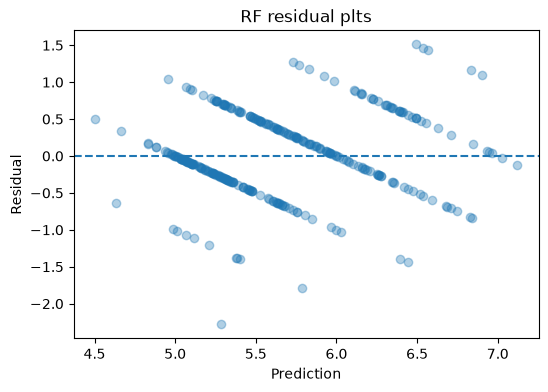

In [13]:
fig, ax = plt.subplots(figsize=(5,5))
ax.scatter(y_valid, pred_rf, alpha=0.35)
ax.plot(
    [y_valid.min(), y_valid.max()], 
    [y_valid.min(), y_valid.max()],
    "--"
)
ax.set(xlabel='Actual', ylabel='Predicted')
plt.title("RF prediction accuracy")
plt.show()

resid_rf = y_valid.to_numpy() - pred_rf
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(pred_rf, resid_rf, alpha=0.35)
ax.axhline(0, ls='--')
ax.set(xlabel='Prediction', ylabel='Residual')
plt.title("RF residual plts")
plt.show()

In [25]:
y_vs_pred_rf = pd.DataFrame(
    {'y': y_valid.to_numpy(), 'pred': pred_rf}
)

y_vs_pred_rf['sq_error'] = (y_vs_pred_rf['y'] - y_vs_pred_rf['pred'])**2

rmse_by_y = y_vs_pred_rf.groupby('y')['sq_error'].mean().pow(0.5)

rmse_by_y


y
3    2.282120
4    1.233129
5    0.419879
6    0.465416
7    0.693584
8    1.343869
Name: sq_error, dtype: float64

## F. Permutation importance
Top 5 features for preferred model.

In [26]:
pi=permutation_importance(
    rf,X_valid,y_valid,
    n_repeats=10,random_state=42,
    scoring="neg_mean_squared_error")

imp=pd.Series(pi.importances_mean,index=X.columns).sort_values(ascending=False)
print(imp.head(5))

alcohol                 0.237492
sulphates               0.138016
volatile acidity        0.083987
total sulfur dioxide    0.039855
pH                      0.013165
dtype: float64


## G. Explain aloud
Baseline? scaling? Ridge vs tree? why bucket errors? leakage?